In [1]:
import numpy as np
import xarray as xr
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA
import rasterio
import torch
from einops import rearrange

PATH_LABEL = "/home/hkerino/Documents/nextoso-dataset/data/10m/labels"
PATH_PLOT_S2 = "/home/hkerino/Documents/nextoso-dataset/data/10m/plots/S2_one_timestep"
PATH_embedding = "/home/hkerino/Documents/nextoso-dataset/data/10m/embeddings_data"
path_oso_class = (
    "/home/hkerino/Documents/nextoso-dataset/data/auxiliary/OSO/oso_classes.csv"
)

## Functions

In [2]:
from templates.constants import cmap_oso, names_class


def plot_label(label):
    fig, ax = plt.subplots()
    im = ax.imshow(label, cmap=cmap_oso, vmin=0, vmax=24)
    cbar = fig.colorbar(im, ticks=np.arange(0, 25))
    cbar.ax.set_yticklabels([names_class[i] for i in range(25)])
    ax.axis("off")


def plot_emb(id, figsize=(20, 5)):
    id = f"{id:04d}"
    # label
    label = xr.open_dataset(f"{PATH_LABEL}/label_{id}.nc")["max_class_1"].data

    # s2 plot
    with rasterio.open(f"{PATH_PLOT_S2}/s2_{id}.tif") as src:
        b1 = src.read(1)
        b2 = src.read(2)
        b3 = src.read(3)

    img_s2 = np.dstack((b1, b2, b3))

    # Alpha earth
    alpha_earth_npy = np.load(f"{PATH_embedding}/alpha-earth_data/alpha-earth_{id}.npy")
    X = alpha_earth_npy.reshape(64, -1).T
    pca = PCA(n_components=3)
    rgb = pca.fit_transform(X)
    rgb = rgb.reshape(128, 128, 3)
    img_alpha_earth = (rgb - rgb.min()) / (rgb.max() - rgb.min())

    # npy
    data_tessera_npy = np.load(f"{PATH_embedding}/tessera_data/tessera_{id}.npy")
    X = data_tessera_npy.reshape(128, -1).T
    pca = PCA(n_components=3)
    rgb = pca.fit_transform(X)
    rgb = rgb.reshape(128, 128, 3)
    img_tessera = (rgb - rgb.min()) / (rgb.max() - rgb.min())

    # plot
    fig, axs = plt.subplots(1, 4, figsize=figsize)

    axs[0].imshow(img_s2)
    axs[0].set_title("S2 Image")
    axs[0].axis("off")

    axs[1].imshow(img_alpha_earth)
    axs[1].set_title("Alpha Earth PCA")
    axs[1].axis("off")

    axs[2].imshow(img_tessera)
    axs[2].set_title("Tessera PCA")
    axs[2].axis("off")

    im = axs[3].imshow(label, cmap=cmap_oso, vmin=0, vmax=24)
    cbar = fig.colorbar(im, ticks=np.arange(0, 25))
    cbar.ax.set_yticklabels([names_class[i] for i in range(25)])
    axs[3].set_title("Label")
    axs[3].axis("off")
    plt.tight_layout()
    plt.show()

## Plot

/tmp/ipykernel_31263/3441983882.py:16: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b1 = src.read(1)
/tmp/ipykernel_31263/3441983882.py:17: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b2 = src.read(2)
/tmp/ipykernel_31263/3441983882.py:18: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b3 = src.read(3)


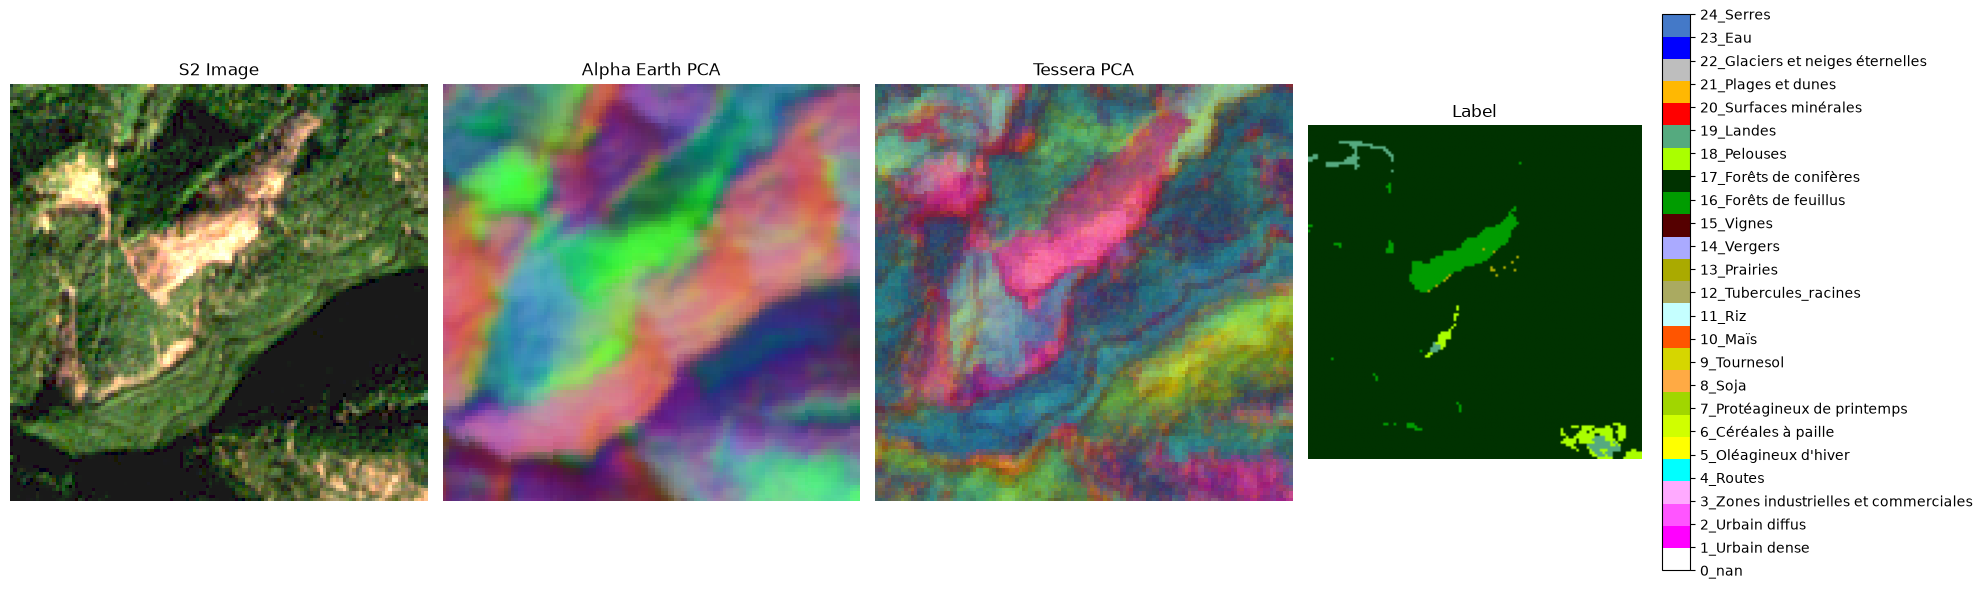

In [11]:
plot_emb(1640, figsize=(20, 6))

## Plot all

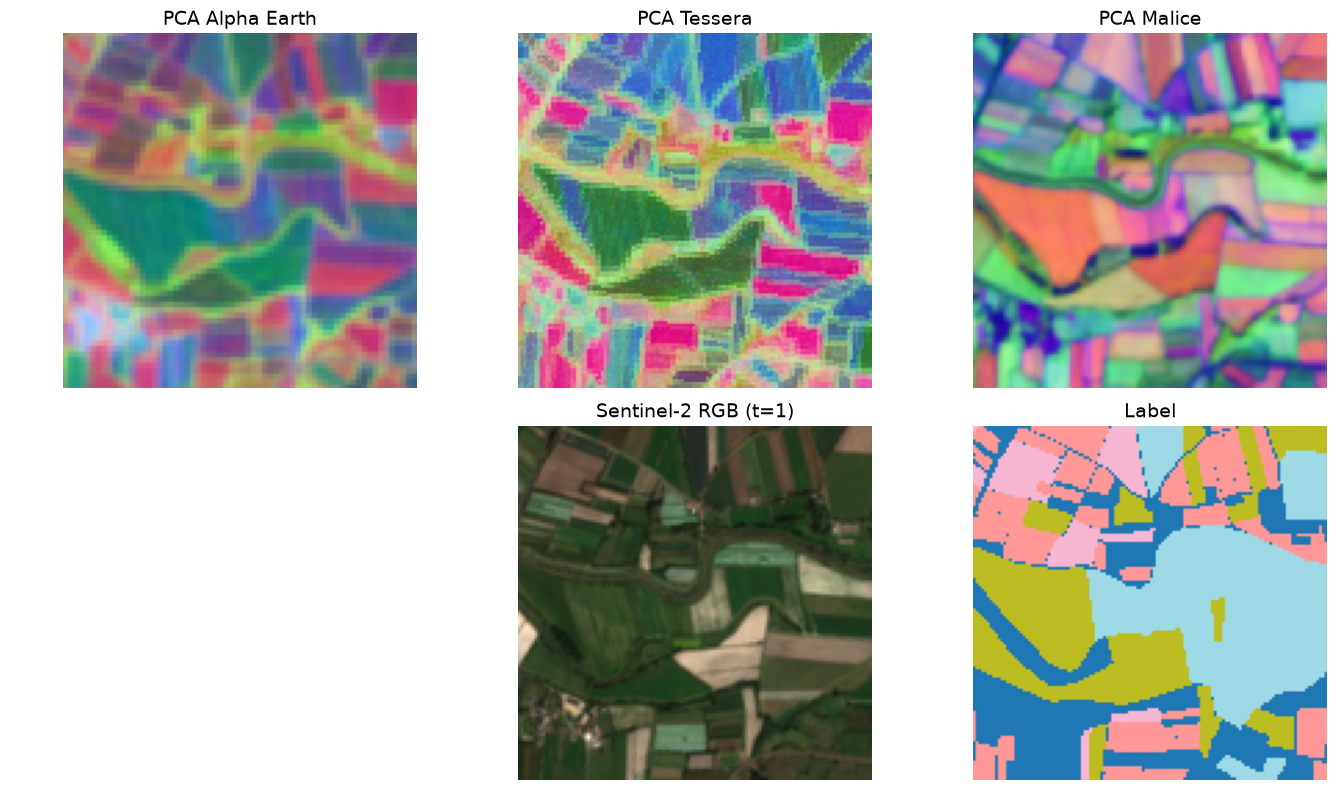

In [14]:
# Charger le label et S2
PATH_PASTIS = "/home/hkerino/Documents/PASTIS"

id = "10006"
ae = np.load(f"{PATH_PASTIS}/embeddings_data/alpha-earth_data/alpha-earth_{id}.npy")
te = np.load(f"{PATH_PASTIS}/embeddings_data/tessera_data/tessera_{id}.npy")
malice = torch.load(f"{PATH_PASTIS}/embeddings_data/malice_data/MALICE_{id}.pt")
label = np.load(f"{PATH_PASTIS}/ANNOTATIONS/ParcelIDs_{id}.npy")
s2 = np.load(f"{PATH_PASTIS}/DATA_S2/S2_{id}.npy")

# pca
X = ae.reshape(64, -1).T
pca = PCA(n_components=3)
rgb = pca.fit_transform(X)
rgb = rgb.reshape(128, 128, 3)
img_alpha_earth = (rgb - rgb.min()) / (rgb.max() - rgb.min())

# pca
X = te.reshape(128, -1).T
pca = PCA(n_components=3)
rgb = pca.fit_transform(X)
rgb = rgb.reshape(128, 128, 3)
img_tessera = (rgb - rgb.min()) / (rgb.max() - rgb.min())

# pca
malice_r = rearrange(malice, "t c h w -> (t c) h w")
X = malice_r.reshape(640, -1).T
pca = PCA(n_components=3)
rgb = pca.fit_transform(X)
rgb = rgb.reshape(128, 128, 3)
img_malice = (rgb - rgb.min()) / (rgb.max() - rgb.min())

# Sélectionner un timestep et extraire les 3 bandes RGB
# S2 shape: (T, C, H, W) - sélectionner t=0 et bandes RGB [2, 1, 0] (Red, Green, Blue)
t = 1
s2_rgb = s2[t, [2, 1, 0], :, :].transpose(1, 2, 0)  # (H, W, 3)

# Normaliser S2 entre 0 et 1
s2_rgb = np.clip(s2_rgb / 3000, 0, 1)  # Sentinel-2 a des valeurs jusqu'à ~3000

# Plotter PCA RGB, S2 RGB et label
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0, 0].imshow(img_alpha_earth)
axes[0, 0].set_title("PCA Alpha Earth", fontsize=14)
axes[0, 0].axis("off")

axes[0, 1].imshow(img_tessera)
axes[0, 1].set_title("PCA Tessera", fontsize=14)
axes[0, 1].axis("off")

axes[0, 2].imshow(img_malice)
axes[0, 2].set_title("PCA Malice", fontsize=14)
axes[0, 2].axis("off")

axes[1, 1].imshow(s2_rgb)
axes[1, 1].set_title(f"Sentinel-2 RGB (t={t})", fontsize=14)
axes[1, 1].axis("off")

axes[1, 2].imshow(label, cmap="tab20")
axes[1, 2].set_title("Label", fontsize=14)
axes[1, 2].axis("off")
axes[1, 0].axis("off")

plt.tight_layout()
plt.show()